# Personalizzazione dei grafici: scheda di riferimento

Corso Python per l'analisi dei dati, CNR, Area di Ricerca di Firenze

Questo notebook è un ricettario da tenere aperto accanto agli esercizi e da riusare
dopo il corso. Ogni voce è un caso reale, con la riga di codice
che lo risolve e la figura che ne esce.

Non c'è niente da imparare a memoria. Serve sapere che il caso esiste e dove ritrovarlo.

### Come è organizzato

| | Sezione |
|---|---|
| 1 | Linee e marcatori |
| 2 | Assi |
| 3 | Testo e annotazioni sul grafico |
| 4 | Legende |
| 5 | Barre d'errore e bande di incertezza |
| 6 | Colori |
| 7 | Pannelli multipli e assi doppi |
| 8 | Salvataggio per la pubblicazione |
| 9 | Tranelli ricorrenti |

### Una convenzione, sempre la stessa

Tutti gli esempi usano la forma esplicita:

```python
fig, ax = plt.subplots()
ax.plot(x, y)
```

e non `plt.plot(...)`. La differenza conta: `plt.` agisce su un grafico "corrente"
implicito, e appena ci sono due pannelli o si torna indietro a modificare una figura,
diventa imprevedibile. Con `fig` e `ax` si dice sempre *a quale* oggetto si sta parlando.
Nella documentazione e su Stack Overflow si trovano entrambe le forme: sapere che sono
la stessa cosa scritta in due modi evita metà della confusione.

Tutte le celle qui sotto presuppongono che sia stata eseguita **la cella 0** (dati di esempio).

---
## 0. Dati di esempio

Dati sintetici che imitano quelli di un laboratorio: una retta di taratura,
una serie di voltammogrammi a concentrazione crescente, una cinetica di degradazione,
e misure ripetute su gruppi di campioni.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

# resa a schermo: comoda per consultare, non è lo stile da pubblicazione (vedi sez. 8)
mpl.rcParams.update({
    "figure.figsize": (5.2, 3.3),
    "figure.dpi": 110,
    "font.size": 9,
    "axes.grid": False,
})

# --- retta di taratura: concentrazione (uM) -> corrente di picco (uA)
conc = np.array([0.5, 1, 2, 5, 10, 20, 50, 100])
segnale = 0.42 * conc + 0.15 + rng.normal(0, 0.25, conc.size)

# --- voltammogrammi: picco gaussiano su fondo inclinato, a 5 concentrazioni
E = np.linspace(-0.6, 0.2, 400)          # potenziale, V vs Ag/AgCl
conc_vamm = np.array([2, 5, 10, 25, 50])  # uM
def voltammogramma(c):
    picco = 0.30 * c**0.75 * np.exp(-((E + 0.22) / 0.055) ** 2)
    fondo = 1.1 + 2.0 * (E + 0.6)
    return picco + fondo + rng.normal(0, 0.02, E.size)
vamm = np.array([voltammogramma(c) for c in conc_vamm])

# --- cinetica: decadimento esponenziale, campionato fitto
t = np.linspace(0, 120, 200)             # minuti
cinetica = 100 * np.exp(-t / 35) + rng.normal(0, 1.5, t.size)

# --- misure ripetute su 4 gruppi di campioni (n = 6 ciascuno)
gruppi = ["Controllo", "Trattato A", "Trattato B", "Trattato C"]
medie_vere = np.array([12.0, 15.5, 14.2, 19.8])
repliche = medie_vere[:, None] + rng.normal(0, 1.6, (4, 6))
medie = repliche.mean(axis=1)
devst = repliche.std(axis=1, ddof=1)

print("Dati pronti.")

Dati pronti.


---
# 1. Linee e marcatori

### 1.1 Spessore, colore, trasparenza

I tre parametri che si toccano più spesso. Lo spessore si misura in **punti tipografici**:
il default di 1.5 pt è pensato per lo schermo; in una figura rimpicciolita a 8 cm
le linee sottili si perdono. Per la stampa si sta tra 0.8 e 1.5 pt.

`alpha` va da 0 (invisibile) a 1 (opaco). Utile quando le curve si sovrappongono:
ma attenzione: **il formato EPS non supporta la trasparenza** e la rende opaca (§ 8).

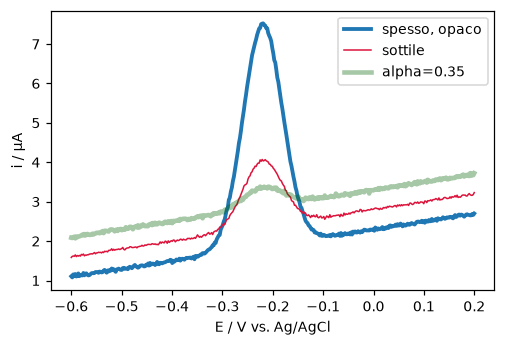

In [2]:
fig, ax = plt.subplots()
ax.plot(E, vamm[4], linewidth=2.5, color="#1f77b4", label="spesso, opaco")
ax.plot(E, vamm[2] + 0.5, linewidth=1.0, color="crimson", label="sottile")
ax.plot(E, vamm[0] + 1.0, linewidth=3.0, color="darkgreen", alpha=0.35, label="alpha=0.35")
ax.set_xlabel("E / V vs. Ag/AgCl")
ax.set_ylabel("i / µA")
ax.legend()
plt.show()

### 1.2 Tratteggio, per sopravvivere al bianco e nero

Se due curve differiscono solo per colore, in bianco e nero diventano indistinguibili.
La soluzione è variare anche il tratteggio.

Le sigle rapide sono `'-'`, `'--'`, `'-.'`, `':'`. Per un controllo fine si usa la
coppia `(offset, (tratto, spazio, tratto, spazio, ...))` in punti.

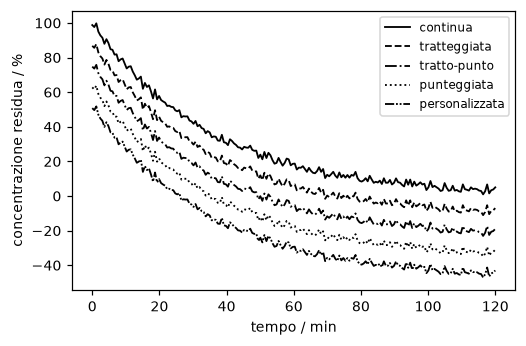

In [3]:
stili = ["-", "--", "-.", ":", (0, (5, 1, 1, 1, 1, 1))]
nomi = ["continua", "tratteggiata", "tratto-punto", "punteggiata", "personalizzata"]

fig, ax = plt.subplots()
for i, (s, n) in enumerate(zip(stili, nomi)):
    ax.plot(t, cinetica - i * 12, linestyle=s, color="black", linewidth=1.2, label=n)
ax.set_xlabel("tempo / min")
ax.set_ylabel("concentrazione residua / %")
ax.legend(fontsize=8)
plt.show()

### 1.3 Marcatori: forma, dimensione, riempimento

I punti sperimentali si distinguono dalle curve calcolate: **punti = marcatori senza linea**,
**modello = linea senza marcatori**.

`markersize` è in punti; `markerfacecolor='none'` dà il marcatore vuoto, che è più leggibile
quando i punti si accavallano.

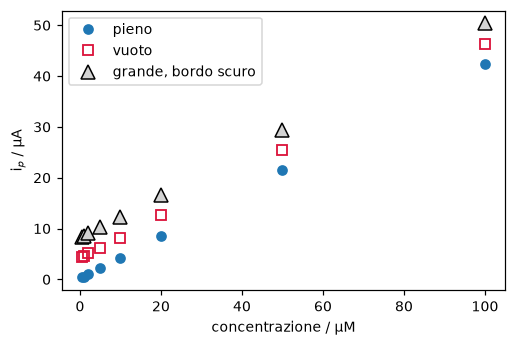

In [4]:
fig, ax = plt.subplots()
ax.plot(conc, segnale, "o", markersize=6, label="pieno")
ax.plot(conc, segnale + 4, "s", markersize=6, markerfacecolor="none",
        markeredgecolor="crimson", markeredgewidth=1.2, label="vuoto")
ax.plot(conc, segnale + 8, "^", markersize=9, markerfacecolor="lightgray",
        markeredgecolor="black", label="grande, bordo scuro")
ax.set_xlabel("concentrazione / µM")
ax.set_ylabel("i$_p$ / µA")
ax.legend()
plt.show()

# forme più usate:  o  s  ^  v  D  *  x  +  .

### 1.4 Marcatori solo su alcuni punti (`markevery`)

Su una curva campionata fitta (200-2000 punti) mettere un marcatore per punto produce
una striscia nera illeggibile. `markevery=N` ne disegna uno ogni N: si distinguono le
curve fra loro senza nascondere il dato.

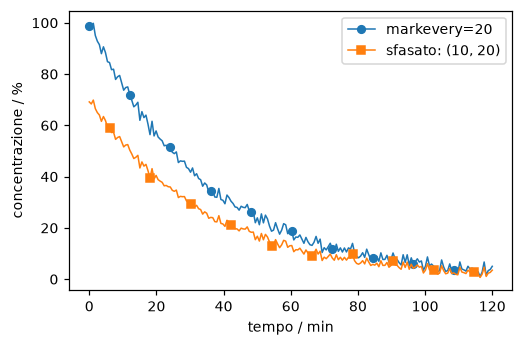

In [5]:
fig, ax = plt.subplots()
ax.plot(t, cinetica, marker="o", markevery=20, markersize=5, linewidth=1.0, label="markevery=20")
ax.plot(t, cinetica * 0.7, marker="s", markevery=(10, 20), markersize=5,
        linewidth=1.0, label="sfasato: (10, 20)")
ax.set_xlabel("tempo / min")
ax.set_ylabel("concentrazione / %")
ax.legend()
plt.show()

### 1.5 Chi sta sopra a chi (`zorder`)

Quando punti e curva si sovrappongono, l'ordine di disegno decide la leggibilità.
Il default è l'ordine delle chiamate; `zorder` lo forza. Numero più alto = più in alto.

Nel caso tipico (punti sperimentali su una retta di regressione) si vuole la retta sotto.

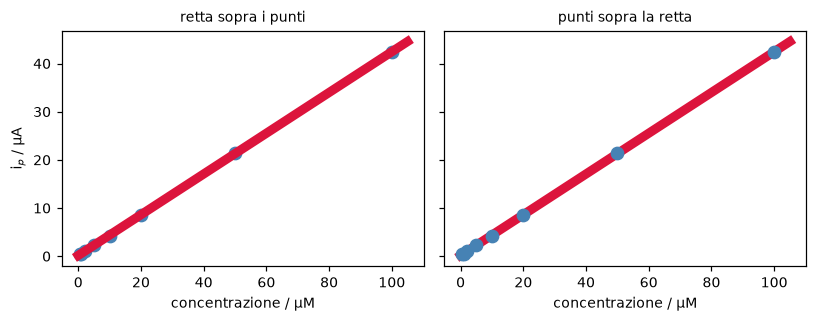

In [6]:
p = np.polyfit(conc, segnale, 1)
xr = np.linspace(0, 105, 50)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.5, 3.0), sharey=True)
for ax, z, titolo in [(a1, 1, "retta sopra i punti"), (a2, 3, "punti sopra la retta")]:
    ax.plot(xr, np.polyval(p, xr), color="crimson", linewidth=6, zorder=2)
    ax.plot(conc, segnale, "o", markersize=8, color="steelblue", zorder=z)
    ax.set_title(titolo, fontsize=9)
    ax.set_xlabel("concentrazione / µM")
a1.set_ylabel("i$_p$ / µA")
fig.tight_layout()
plt.show()

---
# 2. Assi

### 2.1 Limiti e margini

Due modi di decidere l'intervallo mostrato. `set_xlim` / `set_ylim` lo impongono;
`margins` lascia decidere a Matplotlib ma regola l'aria attorno ai dati (default 5%).

`ax.set_ylim(bottom=0)` con il secondo estremo lasciato automatico è il caso
più utile: **forza lo zero senza fissare il massimo**. Sui grafici a barre troncare l'asse
esagera visivamente le differenze.

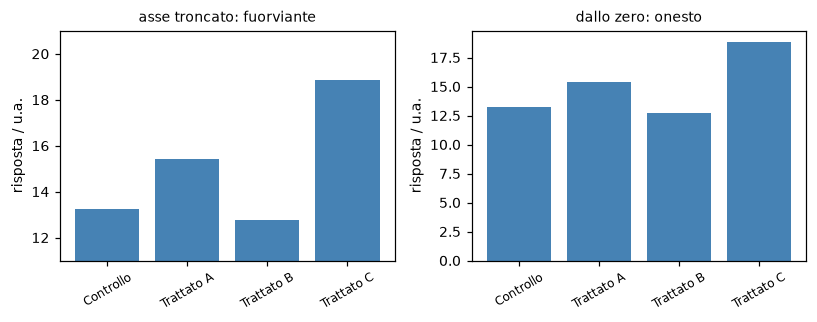

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.5, 3.0))

a1.bar(gruppi, medie, color="steelblue")
a1.set_ylim(11, 21)
a1.set_title("asse troncato: fuorviante", fontsize=9)

a2.bar(gruppi, medie, color="steelblue")
a2.set_ylim(bottom=0)          # massimo automatico
a2.set_title("dallo zero: onesto", fontsize=9)

for ax in (a1, a2):
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.set_ylabel("risposta / u.a.")
fig.tight_layout()
plt.show()

### 2.2 Tick maggiori e minori

I tick automatici vanno bene quasi sempre. Si interviene quando servono passi
"parlanti" (ogni 0.1 V, ogni 10 minuti) o quando si vogliono i tick minori,
che aiutano a leggere valori intermedi senza affollare la figura di numeri.

`tick_params` controlla direzione, lunghezza e su quali lati compaiono.

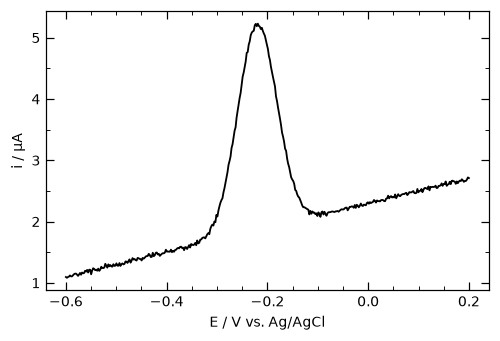

In [8]:
from matplotlib.ticker import MultipleLocator, AutoMinorLocator

fig, ax = plt.subplots()
ax.plot(E, vamm[3], color="black", linewidth=1.2)

ax.xaxis.set_major_locator(MultipleLocator(0.2))   # un numero ogni 0.2 V
ax.xaxis.set_minor_locator(AutoMinorLocator(4))    # 3 tacche in mezzo
ax.yaxis.set_minor_locator(AutoMinorLocator(2))

ax.tick_params(which="both", direction="in", top=True, right=True)
ax.tick_params(which="major", length=5)
ax.tick_params(which="minor", length=2.5)

ax.set_xlabel("E / V vs. Ag/AgCl")
ax.set_ylabel("i / µA")
plt.show()

### 2.3 Formato dei numeri sui tick

Quando i numeri escono con troppe cifre decimali, o servono percentuali, o si vuole
il separatore delle migliaia. `FormatStrFormatter` usa la sintassi di `printf`;
`FuncFormatter` accetta una funzione qualsiasi e copre tutti gli altri casi.

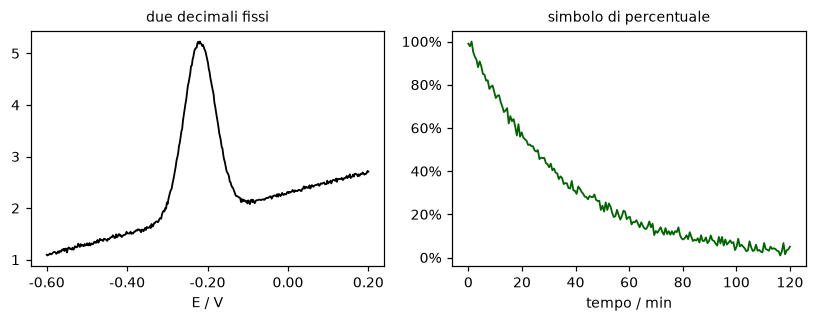

In [9]:
from matplotlib.ticker import FormatStrFormatter, FuncFormatter

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.5, 3.0))

a1.plot(E, vamm[3], color="black", lw=1.2)
a1.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
a1.set_title("due decimali fissi", fontsize=9)
a1.set_xlabel("E / V")

resa = 100 * cinetica / cinetica.max()
a2.plot(t, resa, color="darkgreen", lw=1.2)
a2.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v:.0f}%"))
a2.set_title("simbolo di percentuale", fontsize=9)
a2.set_xlabel("tempo / min")

fig.tight_layout()
plt.show()

### 2.4 Scala logaritmica

Il caso quotidiano: una taratura che copre tre o quattro ordini di grandezza.
In scala lineare i punti bassi si schiacciano sull'origine e non si vede se la
risposta lì è lineare, che è proprio la zona vicino al limite di rilevabilità.

`set_xscale("log")`. Il formatter `LogFormatterSciNotation` scrive $10^{-2}$
invece di 0.01.

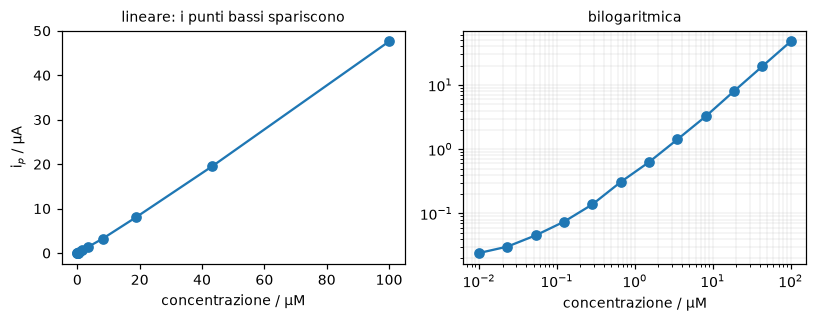

In [10]:
c_wide = np.logspace(-2, 2, 12)                       # 0.01 .. 100 uM
s_wide = 0.42 * c_wide * (1 + rng.normal(0, 0.06, c_wide.size)) + 0.02

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.5, 3.0))

a1.plot(c_wide, s_wide, "o-")
a1.set_title("lineare: i punti bassi spariscono", fontsize=9)

a2.plot(c_wide, s_wide, "o-")
a2.set_xscale("log")
a2.set_yscale("log")
a2.set_title("bilogaritmica", fontsize=9)
a2.grid(True, which="both", linewidth=0.3, alpha=0.5)

for ax in (a1, a2):
    ax.set_xlabel("concentrazione / µM")
a1.set_ylabel("i$_p$ / µA")
fig.tight_layout()
plt.show()

### 2.5 Asse invertito

In voltammetria si disegna spesso il potenziale con i valori negativi a destra;
in spettroscopia infrarossa il numero d'onda è decrescente. `invert_xaxis()` ribalta
l'asse senza toccare i dati.

Nota: `invert_xaxis()` è un interruttore. Chiamarlo due volte riporta al punto di
partenza. Sembra ovvio, ma succede quando si rilancia una cella.

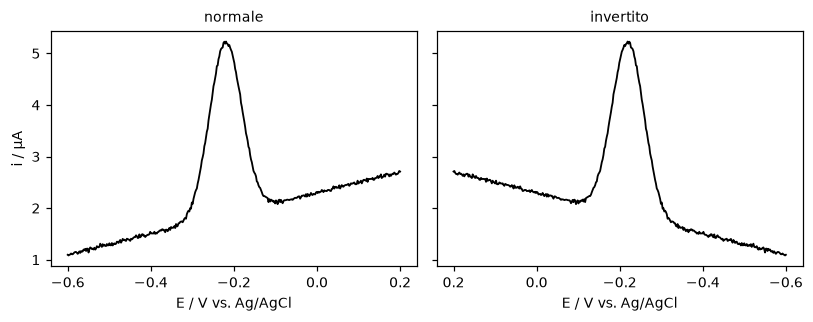

In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.5, 3.0), sharey=True)

a1.plot(E, vamm[3], color="black", lw=1.2)
a1.set_title("normale", fontsize=9)

a2.plot(E, vamm[3], color="black", lw=1.2)
a2.invert_xaxis()
a2.set_title("invertito", fontsize=9)

for ax in (a1, a2):
    ax.set_xlabel("E / V vs. Ag/AgCl")
a1.set_ylabel("i / µA")
fig.tight_layout()
plt.show()

### 2.6 Notazione scientifica e il fattore comune

Quando i valori sono molto grandi o molto piccoli, Matplotlib estrae un fattore comune
e lo scrive in cima all'asse (`1e6`). È compatto ma si legge male in stampa e viene
regolarmente frainteso: molti lettori attribuiscono l'esponente al singolo tick.

Le due alternative: disattivare il fattore, oppure cambiare l'unità di misura
nell'etichetta.

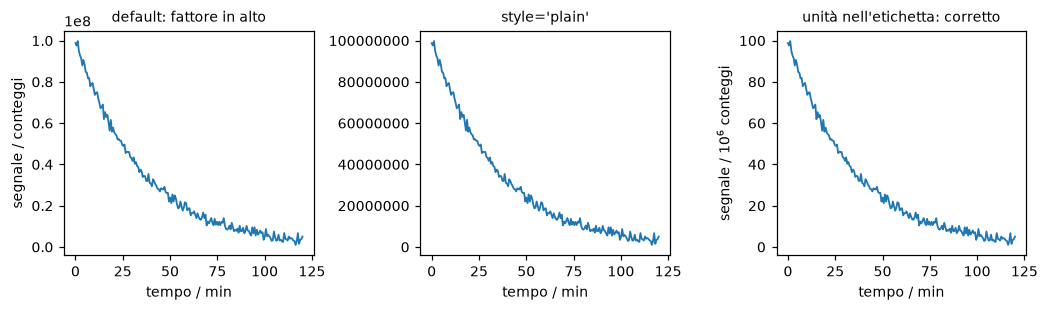

In [12]:
grandi = cinetica * 1e6

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(9.5, 2.9))

a1.plot(t, grandi, lw=1.2)
a1.set_title("default: fattore in alto", fontsize=9)
a1.set_ylabel("segnale / conteggi")

a2.plot(t, grandi, lw=1.2)
a2.ticklabel_format(axis="y", style="plain")
a2.set_title("style='plain'", fontsize=9)

a3.plot(t, grandi / 1e6, lw=1.2)
a3.set_ylabel("segnale / 10$^6$ conteggi")
a3.set_title("unità nell'etichetta: corretto", fontsize=9)

for ax in (a1, a2, a3):
    ax.set_xlabel("tempo / min")
fig.tight_layout()
plt.show()

### 2.7 Griglia e cornice

La griglia va tenuta leggera: deve stare dietro ai dati, non competere. Sottile,
grigia, spesso solo orizzontale.

I quattro lati del riquadro si chiamano *spines* e si tolgono singolarmente. Togliere
il lato destro e superiore è una scelta di stile diffusa, che alleggerisce la figura.

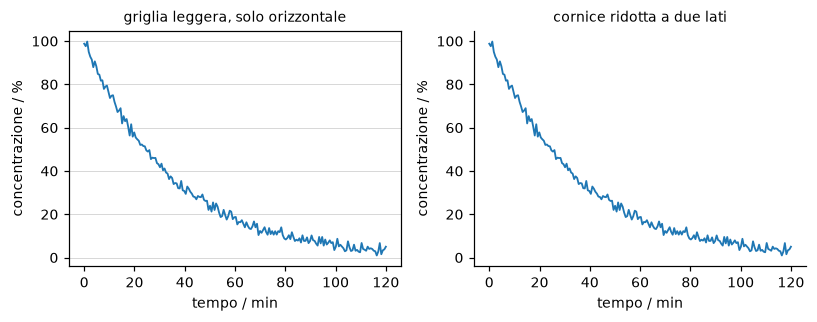

In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.5, 3.0))

a1.plot(t, cinetica, lw=1.2)
a1.grid(True, axis="y", linewidth=0.4, color="gray", alpha=0.5)
a1.set_title("griglia leggera, solo orizzontale", fontsize=9)

a2.plot(t, cinetica, lw=1.2)
a2.spines["top"].set_visible(False)
a2.spines["right"].set_visible(False)
a2.set_title("cornice ridotta a due lati", fontsize=9)

for ax in (a1, a2):
    ax.set_xlabel("tempo / min")
    ax.set_ylabel("concentrazione / %")
fig.tight_layout()
plt.show()

---
# 3. Testo e annotazioni sul grafico

### 3.1 Annotazione con freccia su un picco

`annotate` vuole due punti: `xy` è **dove punta la freccia** (in coordinate dei dati),
`xytext` è **dove sta il testo**. Il dizionario `arrowprops` disegna il collegamento.

`shrink` lascia un po' d'aria fra la punta e il dato, così la freccia non copre il picco.

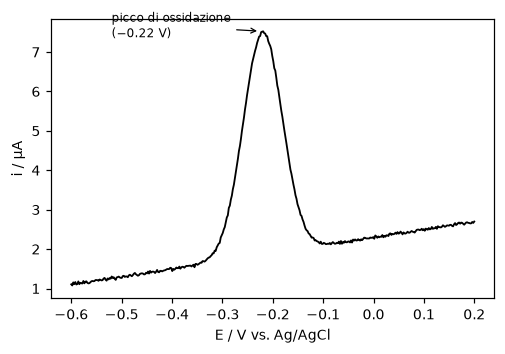

In [14]:
i_picco = np.argmax(vamm[4] - (1.1 + 2.0 * (E + 0.6)))

fig, ax = plt.subplots()
ax.plot(E, vamm[4], color="black", lw=1.2)
ax.annotate("picco di ossidazione\n(−0.22 V)",
            xy=(E[i_picco], vamm[4][i_picco]),
            xytext=(-0.52, vamm[4].max() - 0.15),
            fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=0.8, shrinkB=4))
ax.set_xlabel("E / V vs. Ag/AgCl")
ax.set_ylabel("i / µA")
plt.show()

### 3.2 Equazione e R² dentro il riquadro

Il caso più frequente in assoluto. Il punto chiave è `transform=ax.transAxes`:
le coordinate diventano **frazioni del riquadro** (0,0 in basso a sinistra, 1,1 in alto
a destra) invece che valori dei dati. Così la scritta resta al suo posto anche se
cambiano i dati o i limiti degli assi.

`va` e `ha` (allineamento verticale e orizzontale) dicono quale angolo del testo va
messo in quel punto.

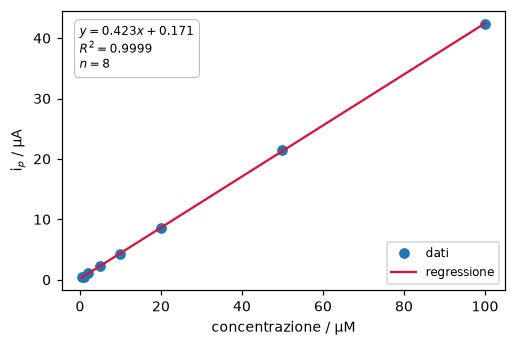

In [15]:
m, q = np.polyfit(conc, segnale, 1)
pred = m * conc + q
r2 = 1 - np.sum((segnale - pred) ** 2) / np.sum((segnale - segnale.mean()) ** 2)

fig, ax = plt.subplots()
ax.plot(conc, segnale, "o", label="dati")
ax.plot(conc, pred, "-", color="crimson", label="regressione")
ax.text(0.04, 0.95,
        f"$y = {m:.3f}x + {q:.3f}$\n$R^2 = {r2:.4f}$\n$n = {conc.size}$",
        transform=ax.transAxes, va="top", ha="left", fontsize=8,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                  edgecolor="0.7", linewidth=0.6))
ax.set_xlabel("concentrazione / µM")
ax.set_ylabel("i$_p$ / µA")
ax.legend(loc="lower right", fontsize=8)
plt.show()

### 3.3 Etichette sui singoli punti

Utile per identificare campioni anomali o pochi punti nominati (tipico nei grafici
dei punteggi PCA). Con più di una decina di punti diventa illeggibile: meglio
etichettare solo quelli che interessano.

L'offset in punti tipografici tramite `textcoords="offset points"` evita che
l'etichetta finisca sopra il marcatore.

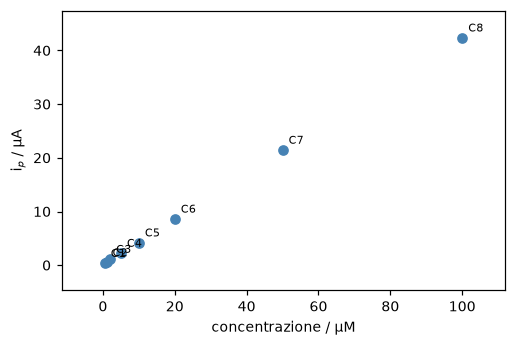

In [16]:
nomi_camp = [f"C{i+1}" for i in range(conc.size)]

fig, ax = plt.subplots()
ax.plot(conc, segnale, "o", color="steelblue")
for x, y, n in zip(conc, segnale, nomi_camp):
    ax.annotate(n, xy=(x, y), xytext=(4, 4),
                textcoords="offset points", fontsize=7)
ax.set_xlabel("concentrazione / µM")
ax.set_ylabel("i$_p$ / µA")
ax.margins(0.12)
plt.show()

### 3.4 Lettere (a) (b) (c) sui pannelli

Stessa tecnica del § 3.2 (`transAxes`) applicata in ciclo, così tutte le lettere
finiscono esattamente nella stessa posizione relativa in ogni pannello.

Coordinate leggermente fuori dal riquadro (x negativo, y > 1) le mettono all'esterno.

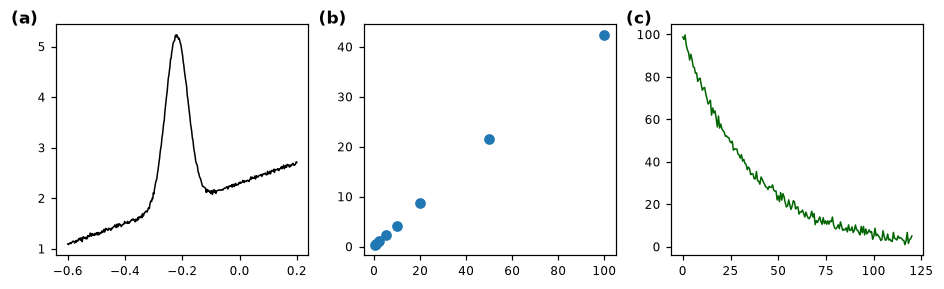

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(8.5, 2.7))
axs[0].plot(E, vamm[3], color="black", lw=1.0)
axs[1].plot(conc, segnale, "o")
axs[2].plot(t, cinetica, color="darkgreen", lw=1.0)

for ax, lettera in zip(axs, "abc"):
    ax.text(-0.18, 1.06, f"({lettera})", transform=ax.transAxes,
            fontsize=11, fontweight="bold", va="top", ha="left")
    ax.tick_params(labelsize=8)

fig.tight_layout()
plt.show()

### 3.5 Apici, pedici, lettere greche

Matplotlib interpreta la sintassi LaTeX dentro `$...$` senza bisogno di avere LaTeX
installato (si chiama *mathtext*). Copre tutto quello che serve nelle etichette
scientifiche.

Va usata la **stringa grezza** `r"..."`: senza la `r`, Python interpreta la barra
rovesciata come carattere di controllo e la formula si rompe in modi poco chiari.

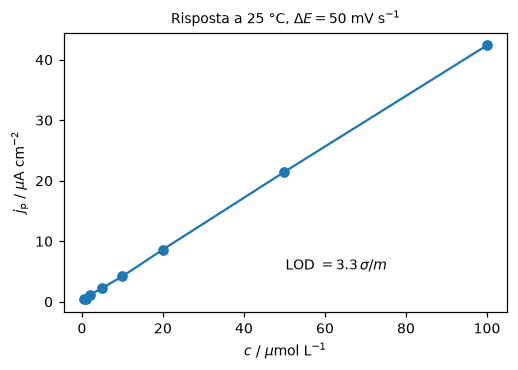

In [18]:
fig, ax = plt.subplots()
ax.plot(conc, segnale, "o-")
ax.set_xlabel(r"$c$ / $\mu$mol L$^{-1}$")
ax.set_ylabel(r"$j_\mathrm{p}$ / $\mu$A cm$^{-2}$")
ax.set_title(r"Risposta a 25 °C, $\Delta E = 50$ mV s$^{-1}$", fontsize=9)
ax.text(0.5, 0.15, r"LOD $= 3.3\,\sigma/m$", transform=ax.transAxes, fontsize=9)
plt.show()

# pedice: x_1   apice: x^2   greche: \alpha \beta \mu \Delta \sigma
# tondo dentro la formula: \mathrm{p}    più di un carattere: x_{max}

---
# 4. Legende

### 4.1 Posizione

`loc="best"` è il default e cerca il punto meno affollato: va bene per guardare al volo,
ma cambia da un rilancio all'altro se i dati cambiano. Per avere sempre la stessa
figura, la posizione va fissata.

Valori: `'upper right'`, `'upper left'`, `'lower left'`, `'lower right'`, `'center left'`, ...

`frameon=False` toglie il riquadro (più pulito su sfondo bianco); `ncol` distribuisce
le voci su più colonne, utile quando la legenda verticale è più alta del grafico.

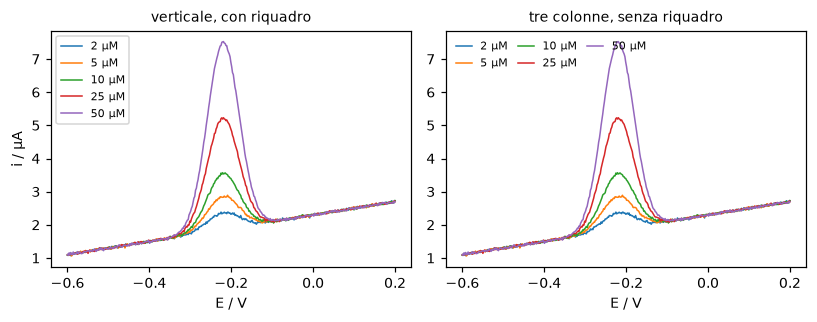

In [19]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.5, 3.0))

for i, c in enumerate(conc_vamm):
    a1.plot(E, vamm[i], lw=1.0, label=f"{c} µM")
    a2.plot(E, vamm[i], lw=1.0, label=f"{c} µM")

a1.legend(loc="upper left", fontsize=7)
a1.set_title("verticale, con riquadro", fontsize=9)

a2.legend(loc="upper left", ncol=3, frameon=False, fontsize=7,
          columnspacing=1.0, handlelength=1.5)
a2.set_title("tre colonne, senza riquadro", fontsize=9)

for ax in (a1, a2):
    ax.set_xlabel("E / V")
a1.set_ylabel("i / µA")
fig.tight_layout()
plt.show()

### 4.2 Legenda fuori dagli assi

Quando le curve sono tante e la legenda copre i dati comunque la si metta. `bbox_to_anchor`
dà la posizione in coordinate del riquadro: valori > 1 la spingono fuori.

Serve `constrained_layout=True` (o `bbox_inches="tight"` al salvataggio), altrimenti
la legenda finisce tagliata dal bordo della figura. È l'inconveniente numero uno di
questa tecnica.

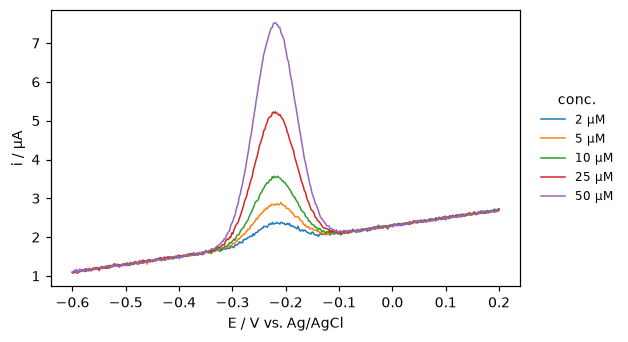

In [20]:
fig, ax = plt.subplots(figsize=(5.6, 3.0), constrained_layout=True)
for i, c in enumerate(conc_vamm):
    ax.plot(E, vamm[i], lw=1.0, label=f"{c} µM")

ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5),
          fontsize=8, frameon=False, title="conc.")
ax.set_xlabel("E / V vs. Ag/AgCl")
ax.set_ylabel("i / µA")
plt.show()

### 4.3 Ordine delle voci

Matplotlib elenca le voci nell'ordine in cui le curve sono state disegnate. Quando
questo non coincide con l'ordine logico (o con l'ordine verticale delle curve sul
grafico), si recuperano gli elementi e si riordinano a mano.

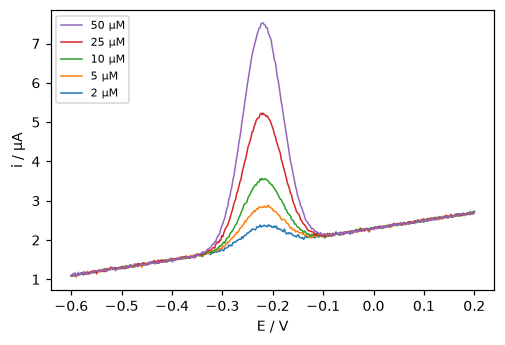

In [21]:
fig, ax = plt.subplots()
for i, c in enumerate(conc_vamm):
    ax.plot(E, vamm[i], lw=1.0, label=f"{c} µM")

handles, labels = ax.get_legend_handles_labels()
ordine = list(range(len(labels)))[::-1]        # decrescente
ax.legend([handles[i] for i in ordine],
          [labels[i] for i in ordine],
          fontsize=7, loc="upper left")
ax.set_xlabel("E / V")
ax.set_ylabel("i / µA")
plt.show()

### 4.4 Escludere una curva dalla legenda

Linee di riferimento, il fondo, la linea dello zero: elementi che devono comparire nel
grafico ma non nella legenda. Due modi: non passare `label`, oppure passare
`label="_nolegend_"`, utile quando l'etichetta serve altrove nel codice.

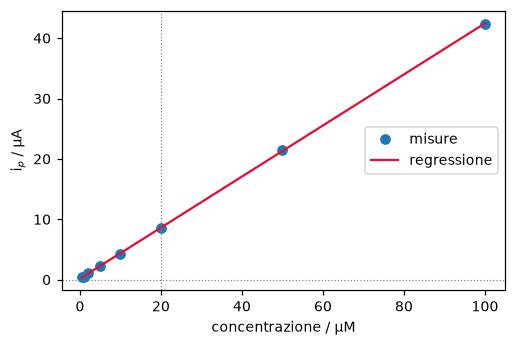

In [22]:
fig, ax = plt.subplots()
ax.plot(conc, segnale, "o", label="misure")
ax.plot(conc, m * conc + q, "-", color="crimson", label="regressione")
ax.axhline(0, color="gray", lw=0.8, linestyle=":", label="_nolegend_")
ax.axvline(20, color="gray", lw=0.8, linestyle=":", label="_nolegend_")
ax.legend()
ax.set_xlabel("concentrazione / µM")
ax.set_ylabel("i$_p$ / µA")
plt.show()

### 4.5 Barra di colore al posto della legenda

Quando le curve rappresentano una **grandezza continua e ordinata** (concentrazioni
crescenti, temperature, tempi) la legenda a voci discrete è la scelta sbagliata:
occupa spazio e nasconde l'ordine. Una barra di colore comunica in un colpo solo
che la variabile è ordinata, e quanto sono spaziati i livelli.

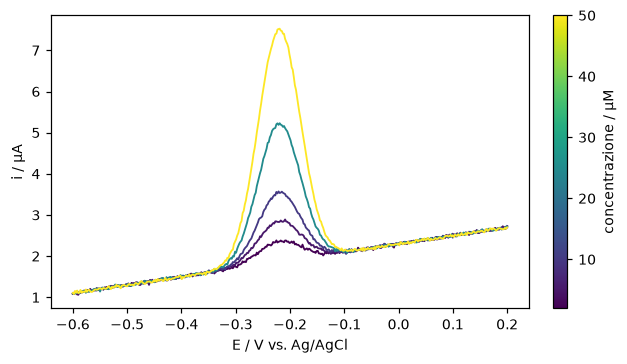

In [23]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

norm = Normalize(vmin=conc_vamm.min(), vmax=conc_vamm.max())
cmap = plt.get_cmap("viridis")

fig, ax = plt.subplots(figsize=(5.6, 3.2), constrained_layout=True)
for i, c in enumerate(conc_vamm):
    ax.plot(E, vamm[i], lw=1.2, color=cmap(norm(c)))

cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax)
cb.set_label("concentrazione / µM")
ax.set_xlabel("E / V vs. Ag/AgCl")
ax.set_ylabel("i / µA")
plt.show()

---
# 5. Barre d'errore e bande di incertezza

### 5.1 Barre d'errore

`yerr` accetta un valore per punto (barra simmetrica) oppure un array `(2, N)`
con estremi inferiore e superiore, per barre asimmetriche.

`capsize` mette i trattini terminali (0 li toglie); `fmt="o"` disegna solo i marcatori,
`fmt="none"` disegna solo le barre. `elinewidth` va tenuto più sottile della linea
dei dati, altrimenti le barre dominano visivamente.

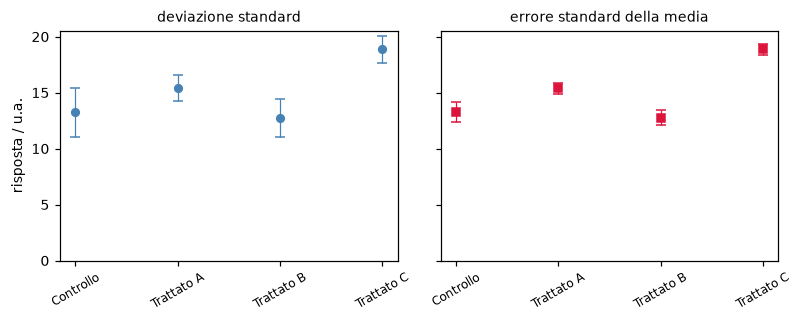

In [24]:
sem = devst / np.sqrt(repliche.shape[1])
x = np.arange(len(gruppi))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.5, 3.0), sharey=True)

a1.errorbar(x, medie, yerr=devst, fmt="o", capsize=3,
            elinewidth=0.8, markersize=5, color="steelblue")
a1.set_title("deviazione standard", fontsize=9)

a2.errorbar(x, medie, yerr=sem, fmt="s", capsize=3,
            elinewidth=0.8, markersize=5, color="crimson")
a2.set_title("errore standard della media", fontsize=9)

for ax in (a1, a2):
    ax.set_xticks(x)
    ax.set_xticklabels(gruppi, rotation=30, fontsize=8)
    ax.set_ylim(bottom=0)
a1.set_ylabel("risposta / u.a.")
fig.tight_layout()
plt.show()

### 5.2 Banda di incertezza

Su una curva continua le barre punto per punto sono illeggibili: si usa una banda
ombreggiata con `fill_between`.

Due avvertenze pratiche: `alpha` bassa (0.15-0.3) perché la banda non deve competere
con la curva, e `zorder` basso per tenerla sotto. E ricordare che in EPS la
trasparenza si perde (§ 8): se serve l'EPS, meglio una banda a tinta piatta
chiara, senza alpha.

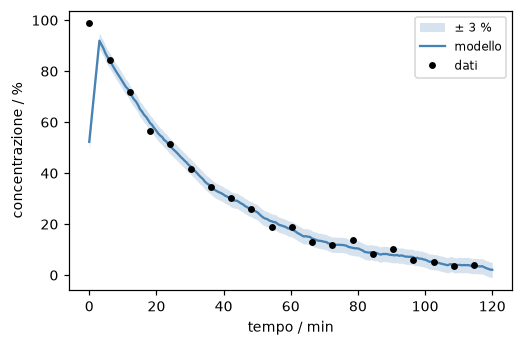

In [25]:
media_mob = np.convolve(cinetica, np.ones(11) / 11, mode="same")
banda = 3.0

fig, ax = plt.subplots()
ax.fill_between(t, media_mob - banda, media_mob + banda,
                color="steelblue", alpha=0.22, linewidth=0, zorder=1,
                label="± 3 %")
ax.plot(t, media_mob, color="steelblue", lw=1.5, zorder=2, label="modello")
ax.plot(t[::10], cinetica[::10], "o", color="black", markersize=3.5,
        zorder=3, label="dati")
ax.set_xlabel("tempo / min")
ax.set_ylabel("concentrazione / %")
ax.legend(fontsize=8)
plt.show()

### 5.3 Barre raggruppate con errore

Il confronto fra condizioni per più gruppi. La logica è manuale: si sposta la posizione
delle barre di mezza larghezza per lato. Con `n` serie e larghezza `w`, la serie `i`
sta in `x + (i - (n-1)/2) * w`.

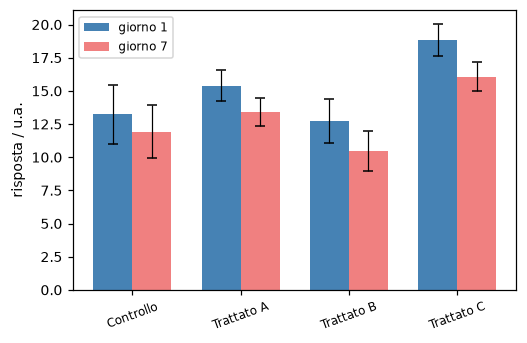

In [26]:
serie_b = medie * 0.85 + rng.normal(0, 0.5, medie.size)
err_b = devst * 0.9
w = 0.36
x = np.arange(len(gruppi))

fig, ax = plt.subplots()
ax.bar(x - w/2, medie, width=w, yerr=devst, capsize=3, label="giorno 1",
       color="steelblue", error_kw=dict(elinewidth=0.8))
ax.bar(x + w/2, serie_b, width=w, yerr=err_b, capsize=3, label="giorno 7",
       color="lightcoral", error_kw=dict(elinewidth=0.8))
ax.set_xticks(x)
ax.set_xticklabels(gruppi, rotation=20, fontsize=8)
ax.set_ylabel("risposta / u.a.")
ax.set_ylim(bottom=0)
ax.legend(fontsize=8)
plt.show()

### 5.4 Box plot con i punti sovrapposti

Con sei repliche per gruppo, il box plot da solo nasconde più di quanto mostri:
quartili calcolati su sei valori sono poco informativi e non si vede se la distribuzione
è bimodale o se c'è un solo campione anomalo a trascinare la media.

Sovrapporre i punti singoli, con un po' di dispersione orizzontale casuale (*jitter*)
per non farli sovrapporre, risolve. Sotto le dieci repliche è quasi sempre la scelta
migliore.

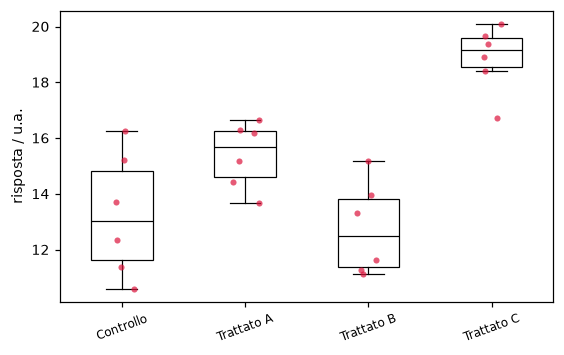

In [27]:
fig, ax = plt.subplots()
bp = ax.boxplot(repliche.T, positions=np.arange(4), widths=0.5,
                showfliers=False, patch_artist=True)
for box in bp["boxes"]:
    box.set(facecolor="white", edgecolor="black", linewidth=0.8)
for elem in ("whiskers", "caps", "medians"):
    for a in bp[elem]:
        a.set(color="black", linewidth=0.8)

for i in range(4):
    jitter = rng.normal(0, 0.055, repliche.shape[1])
    ax.plot(i + jitter, repliche[i], "o", markersize=4,
            color="crimson", alpha=0.7, markeredgewidth=0)

ax.set_xticks(np.arange(4))
ax.set_xticklabels(gruppi, rotation=20, fontsize=8)
ax.set_ylabel("risposta / u.a.")
fig.tight_layout()
plt.show()

---
# 6. Colori

### 6.1 Una palette sicura per i daltonici

Circa un uomo su dodici ha una qualche forma di daltonismo. Il ciclo di colori di
default di Matplotlib non è pensato per questo; le due combinazioni problematiche sono
rosso/verde e, meno nota, verde/marrone.

La palette di Okabe e Ito è quella più usata in ambito scientifico: otto colori
distinguibili con tutti i tipi comuni di daltonismo. Vale la pena impostarla una volta
in cima al notebook e dimenticarsene.

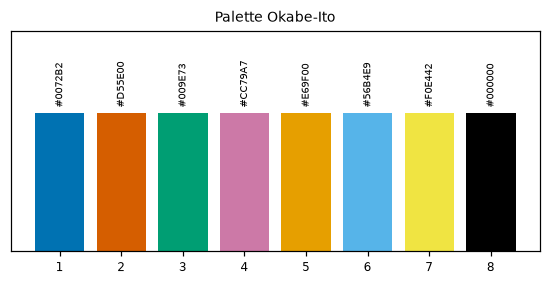

In [28]:
from cycler import cycler

OKABE_ITO = ["#0072B2", "#D55E00", "#009E73", "#CC79A7",
             "#E69F00", "#56B4E9", "#F0E442", "#000000"]

mpl.rcParams["axes.prop_cycle"] = cycler(color=OKABE_ITO)

fig, ax = plt.subplots(figsize=(6.2, 2.6))
for i, c in enumerate(OKABE_ITO):
    ax.bar(i, 1, color=c)
    ax.text(i, 1.06, c, ha="center", fontsize=6.5, rotation=90)
ax.set_ylim(0, 1.6)
ax.set_yticks([])
ax.set_xticks(range(8))
ax.set_xticklabels(range(1, 9), fontsize=8)
ax.set_title("Palette Okabe-Ito", fontsize=9)
plt.show()

### 6.2 Mappe di colore: sequenziale, divergente, qualitativa

Tre famiglie per tre significati diversi:

- **sequenziale** (`viridis`, `plasma`, `Blues`) per grandezze che vanno da poco a molto
- **divergente** (`RdBu`, `coolwarm`) quando c'è uno **zero significativo** al centro:
  correlazioni, differenze rispetto a un controllo
- **qualitativa** (`tab10`, Okabe-Ito) per categorie senza ordine

Da evitare `jet` e affini: creano bordi netti dove i dati sono lisci, e in scala di
grigi diventano non monotone.

Per una matrice di correlazione, con divergente, vanno fissati `vmin=-1` e `vmax=1`:
altrimenti il bianco centrale non cade sullo zero.

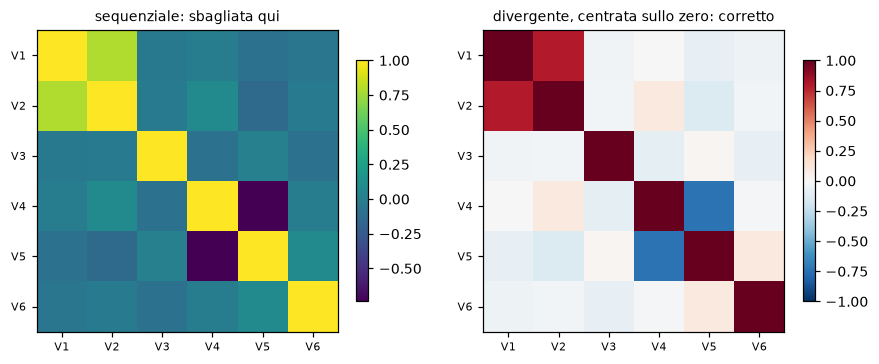

In [29]:
M = rng.normal(size=(60, 6))
M[:, 1] += 1.3 * M[:, 0]
M[:, 4] -= 1.1 * M[:, 3]
corr = np.corrcoef(M, rowvar=False)
etich = [f"V{i+1}" for i in range(6)]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(8.2, 3.2), constrained_layout=True)

im1 = a1.imshow(corr, cmap="viridis")
a1.set_title("sequenziale: sbagliata qui", fontsize=9)
fig.colorbar(im1, ax=a1, shrink=0.8)

im2 = a2.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
a2.set_title("divergente, centrata sullo zero: corretto", fontsize=9)
fig.colorbar(im2, ax=a2, shrink=0.8)

for ax in (a1, a2):
    ax.set_xticks(range(6)); ax.set_xticklabels(etich, fontsize=7)
    ax.set_yticks(range(6)); ax.set_yticklabels(etich, fontsize=7)
plt.show()

### 6.3 Verificare la figura in scala di grigi

Si converte la figura
già disegnata in luminanza e si guarda: se due curve diventano indistinguibili,
servono tratteggi o marcatori diversi (§ 1.2, § 1.3).

Il calcolo usa i pesi standard della luminanza percettiva (0.2126, 0.7152, 0.0722):
il verde pesa più del rosso e molto più del blu, ed è il motivo per cui rosso e verde
di pari intensità collassano sullo stesso grigio.

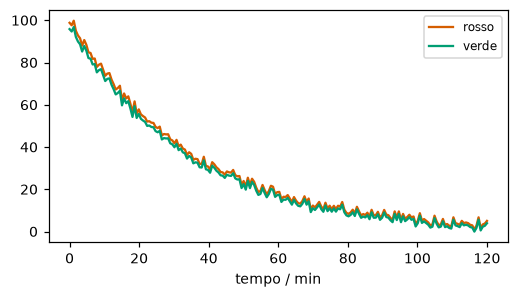

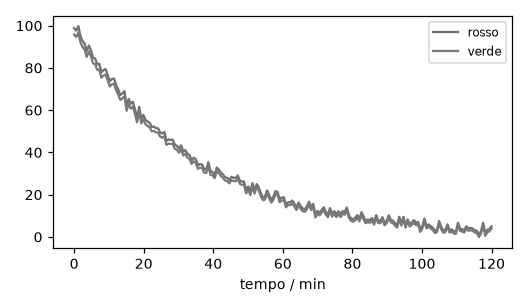

In [30]:
def in_grigi(fig):
    "Restituisce la figura convertita in scala di grigi, per controllo."
    from matplotlib.backends.backend_agg import FigureCanvasAgg
    tela = FigureCanvasAgg(fig)      # funziona anche se la figura è già stata mostrata
    tela.draw()
    rgba = np.asarray(tela.buffer_rgba(), dtype=float) / 255
    lum = rgba[..., :3] @ np.array([0.2126, 0.7152, 0.0722])
    g = plt.figure(figsize=fig.get_size_inches())
    ax = g.add_axes([0, 0, 1, 1]); ax.axis("off")
    ax.imshow(lum, cmap="gray", vmin=0, vmax=1)
    return g

# caso limite: due curve che differiscono SOLO per colore
fig, ax = plt.subplots(figsize=(4.6, 2.6), constrained_layout=True)
ax.plot(t, cinetica, color="#D55E00", lw=1.5, label="rosso")
ax.plot(t, cinetica * 0.98 - 1, color="#009E73", lw=1.5, label="verde")
ax.legend(fontsize=8); ax.set_xlabel("tempo / min")
plt.show()

in_grigi(fig)
plt.show()

---
# 7. Pannelli multipli e assi doppi

### 7.1 Pannelli con assi condivisi

`sharex` / `sharey` fanno due cose insieme: **impongono gli stessi limiti** a tutti i
pannelli (stessa scala, confronto diretto) e tolgono le
etichette ripetute, guadagnando spazio.

`fig.supxlabel` mette una sola etichetta comune per tutta la figura.

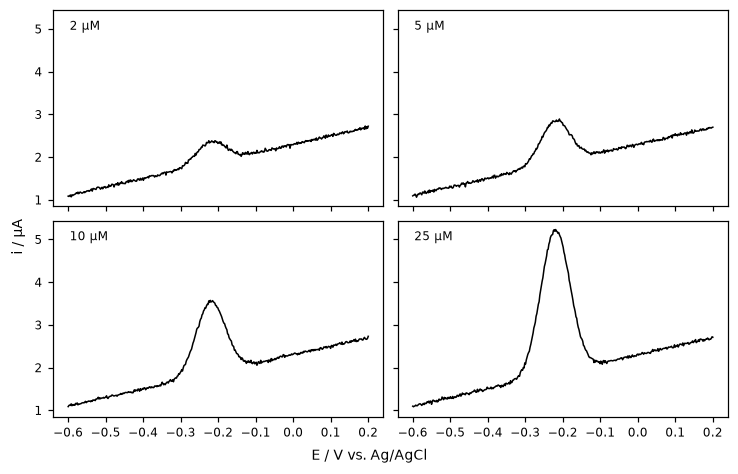

In [31]:
fig, axs = plt.subplots(2, 2, figsize=(6.6, 4.2), sharex=True, sharey=True,
                        constrained_layout=True)
for ax, i, c in zip(axs.flat, range(4), conc_vamm[:4]):
    ax.plot(E, vamm[i], color="black", lw=1.0)
    ax.text(0.05, 0.9, f"{c} µM", transform=ax.transAxes, fontsize=8)
    ax.tick_params(labelsize=8)
fig.supxlabel("E / V vs. Ag/AgCl", fontsize=9)
fig.supylabel("i / µA", fontsize=9)
plt.show()

### 7.2 Doppio asse y

Due grandezze con unità diverse sullo stesso tempo. `twinx()` crea un secondo sistema
di assi che condivide l'asse x.

Due accorgimenti obbligatori: colorare le etichette e i tick in tinta con la
rispettiva curva, altrimenti non si capisce quale asse legga cosa; e costruire una
legenda unica sommando gli elementi dei due assi, perché altrimenti ne escono due
sovrapposte.

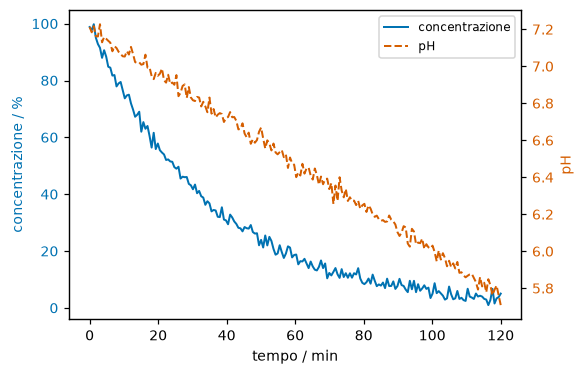

In [32]:
ph = 7.2 - 0.012 * t + rng.normal(0, 0.03, t.size)

fig, a1 = plt.subplots(constrained_layout=True)
l1, = a1.plot(t, cinetica, color="#0072B2", lw=1.3, label="concentrazione")
a1.set_xlabel("tempo / min")
a1.set_ylabel("concentrazione / %", color="#0072B2")
a1.tick_params(axis="y", labelcolor="#0072B2")

a2 = a1.twinx()
l2, = a2.plot(t, ph, color="#D55E00", lw=1.3, linestyle="--", label="pH")
a2.set_ylabel("pH", color="#D55E00")
a2.tick_params(axis="y", labelcolor="#D55E00")

a1.legend(handles=[l1, l2], loc="upper right", fontsize=8)
plt.show()

### 7.3 Riquadro ingrandito (*inset*)

Per mostrare insieme il quadro generale e un dettaglio: la zona vicino al limite di
rilevabilità, la coda di una cinetica, la base di un picco.

`inset_axes` prende `[x, y, larghezza, altezza]` in frazioni del riquadro principale.
`indicate_inset_zoom` disegna il rettangolo sulla zona ingrandita e le linee di
collegamento, che sono ciò che rende leggibile la costruzione.

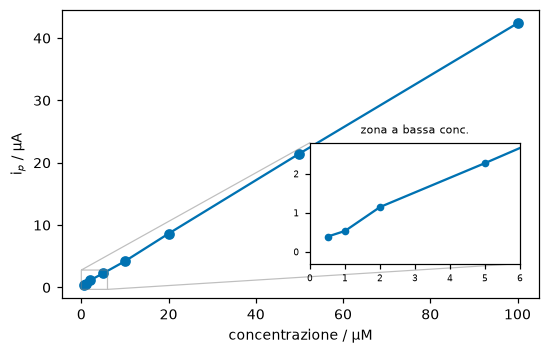

In [33]:
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(conc, segnale, "o-", color="#0072B2")
ax.set_xlabel("concentrazione / µM")
ax.set_ylabel("i$_p$ / µA")

axins = ax.inset_axes([0.52, 0.12, 0.44, 0.42])
axins.plot(conc, segnale, "o-", color="#0072B2", markersize=4)
axins.set_xlim(0, 6)
axins.set_ylim(-0.3, 2.8)
axins.tick_params(labelsize=6)
axins.set_title("zona a bassa conc.", fontsize=7)

ax.indicate_inset_zoom(axins, edgecolor="gray", linewidth=0.8)
plt.show()

### 7.4 Sistemare gli spazi: `constrained_layout`

Il problema classico: etichette tagliate ai bordi, o pannelli che si sovrappongono.

`constrained_layout=True` alla creazione della figura calcola gli spazi in modo che
niente si sovrapponga; è più robusto del vecchio `tight_layout()`, soprattutto con
barre di colore e legende esterne.

Se serve controllo manuale c'è `fig.subplots_adjust(left=..., wspace=...)`, ma nel 90 %
dei casi non serve.

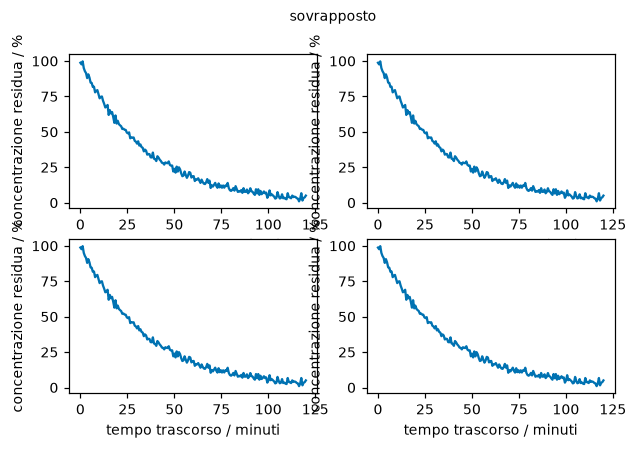

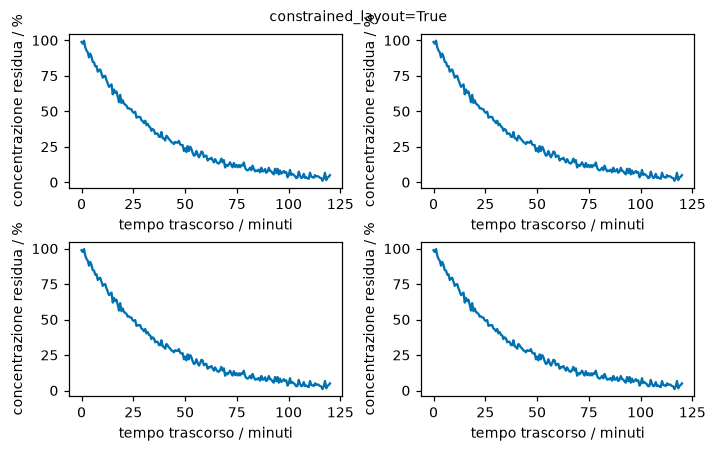

In [34]:
fig, axs = plt.subplots(2, 2, figsize=(6.4, 4.0))   # senza aggiustamenti
for ax in axs.flat:
    ax.plot(t, cinetica)
    ax.set_xlabel("tempo trascorso / minuti")
    ax.set_ylabel("concentrazione residua / %")
fig.suptitle("sovrapposto", fontsize=9)
plt.show()

fig, axs = plt.subplots(2, 2, figsize=(6.4, 4.0), constrained_layout=True)
for ax in axs.flat:
    ax.plot(t, cinetica)
    ax.set_xlabel("tempo trascorso / minuti")
    ax.set_ylabel("concentrazione residua / %")
fig.suptitle("constrained_layout=True", fontsize=9)
plt.show()

---
# 8. Salvataggio per la pubblicazione

Questa parte è coperta dal modulo `figure_pubblicazione.py`. Qui solo il minimo indispensabile da ricordare.

```python
from figure_pubblicazione import stile_rivista, LARGHEZZE, salva_figura

stile_rivista()                                  # font, spessori, dimensioni tick
fig, ax = plt.subplots(figsize=(LARGHEZZE["acs_singola"], 2.6))
...
salva_figura(fig, "figura1", formati=("pdf", "png"))
```

Le quattro cose da non dimenticare:

1. **La larghezza si fissa alla creazione**, non ridimensionando dopo. Se si disegna a
   una larghezza e poi la si rimpicciolisce, il testo si rimpicciolisce con lei.
   Si disegna già alla larghezza finale.
2. **Raster e vettoriale dalla stessa chiamata**: `formati=("pdf", "png")` produce i due
   file insieme, così restano sempre allineati.
3. **`pdf.fonttype = 42`.** Il default di Matplotlib è 3, che trasforma i caratteri in
   disegni: testo non selezionabile e resa peggiore.
   La verifica pratica: aprire il PDF e provare a selezionare il testo con il mouse.
4. **`bbox_inches="tight"`** al salvataggio, altrimenti legende esterne ed etichette
   lunghe vengono tagliate.

**Formati.** Vettoriali: PDF, EPS, SVG. Raster: PNG, TIFF, JPEG.
Per i grafici mai JPEG: la compressione lascia aloni attorno alle linee nette.
E in EPS la trasparenza non esiste: le bande con `alpha` diventano opache
(Matplotlib avvisa, ma l'avviso è facile da perdere in un notebook).

---
# 9. Tranelli ricorrenti

| Sintomo | Causa | Rimedio |
|---|---|---|
| La figura non compare | manca `plt.show()`, o si è già chiusa | `plt.show()` in fondo alla cella |
| Ogni cella ridisegna sopra la precedente | riuso della stessa `fig` | `fig, ax = plt.subplots()` in ogni cella |
| Le figure si accumulano e la memoria cresce | figure mai chiuse in un ciclo | `plt.close(fig)` dopo il salvataggio |
| Etichette tagliate al bordo | layout non calcolato | `constrained_layout=True` o `bbox_inches="tight"` |
| Il file salvato è diverso da quello a schermo | `savefig` dopo `plt.show()` | salvare prima di `show()` |
| L'immagine salvata è sfocata | dpi del salvataggio troppo basso | `dpi=300` o superiore in `savefig` |
| Il testo del PDF non si seleziona | `pdf.fonttype = 3` (default) | `mpl.rcParams["pdf.fonttype"] = 42` |
| Le bande trasparenti sono opache in EPS | PostScript non supporta l'alpha | usare PDF, o tinta piatta chiara |
| Il font non è quello impostato | font non installato, sostituito in silenzio | controllare il messaggio `findfont` |
| La legenda cambia posto a ogni rilancio | `loc="best"` | fissare `loc` |
| Errore `x and y must have same first dimension` | array di lunghezza diversa | controllare con `len(x), len(y)` |
| La formula LaTeX non viene interpretata | manca la `r` prima delle virgolette | `r"$\mu$A"` |
| Le curve sono indistinguibili in fotocopia | differiscono solo per colore | tratteggi e marcatori diversi (§ 1.2) |
| Le differenze fra barre sembrano enormi | asse y troncato | `set_ylim(bottom=0)` |

---

## Dove cercare quando manca un caso

- **Galleria di Matplotlib** (`matplotlib.org/stable/gallery`): si cerca per immagine e si
  copia il codice. È il modo più veloce: si riconosce il grafico che si vuole e si parte da lì.
- **`plt.plot?`** in una cella Jupyter apre la documentazione della funzione senza uscire dal notebook.
- **`ax.` + Tab** elenca tutti i metodi disponibili: spesso quello che serve si trova leggendo i nomi.